# MobileFaceNet Architecture 

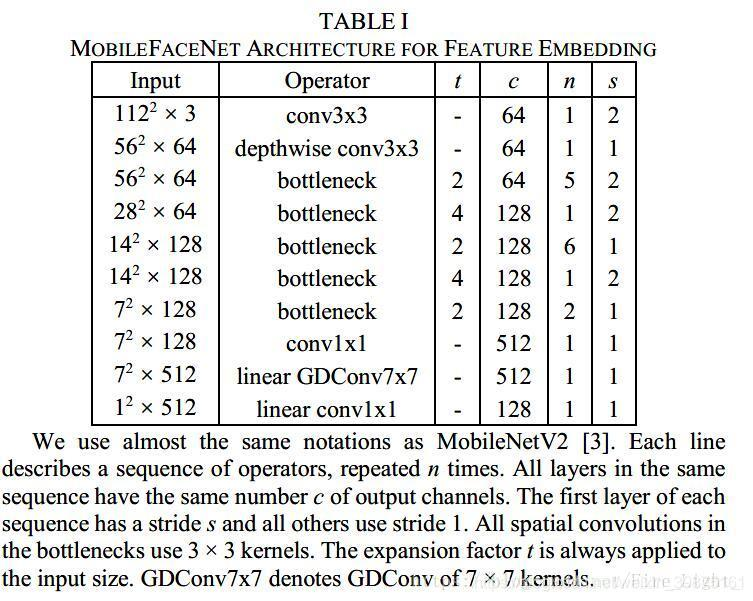

# MobileFaceNet — Bottleneck Block

## 1. Overview
The bottleneck block is the main building block of MobileFaceNet. It extracts useful features while reducing computational cost using **depthwise separable convolution**.

## 2. Block Structure

The bottleneck consists of three main operations:

1. **Expansion (1×1 Convolution)**
   - Increases the number of channels.
   - Expansion factor (`t`) determines the channel increase.
   - Example: 64 → 128 channels when `t = 2`.

2. **Depthwise Convolution (3×3)**
   - Extracts spatial features independently from each channel.
   - Can perform downsampling when stride = 2.
   - Stride = 1 preserves spatial dimensions (with suitable padding).

3. **Projection (1×1 Convolution)**
   - Reduces the expanded channels to the required output channels.
   - Example: 128 → 64 channels.
   - Produces a compact feature representation.

## 3. Example: Bottleneck with t = 2

Input: `28 × 28 × 64`

| Operation | Output shape |
|---|---|
| Input | 28 × 28 × 64 |
| Expansion (1×1) | 28 × 28 × 128 |
| Depthwise (3×3) | 28 × 28 × 128 |
| Projection (1×1) | 28 × 28 × 64 |

## 4. Stride and Repetition

- **Stride = 1:** Preserves spatial dimensions.
- **Stride = 2:** Reduces spatial dimensions approximately by half.
- **Repetition (`n`):** Specifies how many bottleneck blocks are stacked.
- Usually, only the first block in a group uses the specified group stride; subsequent blocks use stride = 1.

## 5. Residual Connection

When input and output dimensions match and stride = 1, a residual connection can be used:

`Output = Bottleneck(Input) + Input`

This helps information and gradients flow through the network.

## 6. Quick Revision

| Component | Main function |
|---|---|
| Expansion | Increases channels |
| Depthwise | Extracts spatial features |
| Projection | Reduces channels |
| Stride | Controls spatial downsampling |
| Repetition | Determines the number of blocks |
| Residual | Adds the input to the block output when dimensions permit |

**Remember:** Expansion changes channel depth, depthwise convolution extracts spatial features, and projection compresses the channels.

# mobilefacenet.py

In [1]:
from pathlib import Path
import sys 

PROJECT_ROOT = Path.cwd().parent
PROJECT_ROOT

WindowsPath('Y:/Python/AI ML/Month 2/week 8-NLP/47 — APPLE FACE ID  (FACIAL RECOGNITION PROJECTS)')

In [2]:
%%writefile "$PROJECT_ROOT/src/mobilefacenet.py"

import torch
import torch.nn as nn


# ============================================================
# 1. CONVOLUTION BLOCK
# ============================================================

class ConvBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        kernel_size,
        stride,
        padding,
        groups=1
    ):
        super().__init__()

        self.conv = nn.Conv2d(
            in_channels=in_channels,
            out_channels=out_channels,
            kernel_size=kernel_size,
            stride=stride,
            padding=padding,
            groups=groups,
            bias=False
        )

        self.bn = nn.BatchNorm2d(out_channels)
        self.prelu = nn.PReLU(out_channels)

    def forward(self, x):

        x = self.conv(x)
        x = self.bn(x)
        x = self.prelu(x)

        return x


# ============================================================
# 2. LINEAR BLOCK
# ============================================================

class LinearBlock(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        kernel_size,
        stride,
        padding,
        groups=1
    ):
        super().__init__()

        self.conv = nn.Conv2d(
            in_channels=in_channels,
            out_channels=out_channels,
            kernel_size=kernel_size,
            stride=stride,
            padding=padding,
            groups=groups,
            bias=False
        )

        self.bn = nn.BatchNorm2d(out_channels)

    def forward(self, x):

        x = self.conv(x)
        x = self.bn(x)

        return x


# ============================================================
# 3. BOTTLENECK BLOCK
# ============================================================

class Bottleneck(nn.Module):

    def __init__(
        self,
        in_channels,
        out_channels,
        expansion,
        stride
    ):
        super().__init__()

        hidden_channels = in_channels * expansion

        # Expansion: 1x1 convolution
        self.expand = ConvBlock(
            in_channels,
            hidden_channels,
            kernel_size=1,
            stride=1,
            padding=0
        )

        # Depthwise: 3x3 convolution
        self.depthwise = ConvBlock(
            hidden_channels,
            hidden_channels,
            kernel_size=3,
            stride=stride,
            padding=1,
            groups=hidden_channels
        )

        # Projection: 1x1 linear convolution
        self.project = LinearBlock(
            hidden_channels,
            out_channels,
            kernel_size=1,
            stride=1,
            padding=0
        )

        # Residual connection
        self.use_residual = (
            stride == 1 and in_channels == out_channels
        )

    def forward(self, x):

        identity = x

        x = self.expand(x)
        x = self.depthwise(x)
        x = self.project(x)

        if self.use_residual:
            x = x + identity

        return x


# ============================================================
# 4. MOBILEFACENET
# ============================================================

class MobileFaceNet(nn.Module):

    def __init__(self, embedding_size=128):
        super().__init__()

        # ----------------------------------------------------
        # Initial Convolution Layers
        # ----------------------------------------------------

        self.conv1 = ConvBlock(
            3, 64,
            kernel_size=3,
            stride=2,
            padding=1
        )

        self.conv2 = ConvBlock(
            64, 64,
            kernel_size=3,
            stride=1,
            padding=1,
            groups=64
        )

        # ----------------------------------------------------
        # Bottleneck Stage 1
        # 64 -> 64, Expansion = 2, Blocks = 5
        # ----------------------------------------------------

        self.stage1 = self._make_stage(
            in_channels=64,
            out_channels=64,
            expansion=2,
            num_blocks=5,
            stride=2
        )

        # ----------------------------------------------------
        # Bottleneck Stage 2
        # 64 -> 128, Expansion = 4, Blocks = 1
        # ----------------------------------------------------

        self.stage2 = self._make_stage(
            in_channels=64,
            out_channels=128,
            expansion=4,
            num_blocks=1,
            stride=2
        )

        # ----------------------------------------------------
        # Bottleneck Stage 3
        # 128 -> 128, Expansion = 2, Blocks = 6
        # ----------------------------------------------------

        self.stage3 = self._make_stage(
            in_channels=128,
            out_channels=128,
            expansion=2,
            num_blocks=6,
            stride=1
        )

        # ----------------------------------------------------
        # Bottleneck Stage 4
        # 128 -> 128, Expansion = 4, Blocks = 1
        # ----------------------------------------------------

        self.stage4 = self._make_stage(
            in_channels=128,
            out_channels=128,
            expansion=4,
            num_blocks=1,
            stride=2
        )

        # ----------------------------------------------------
        # Bottleneck Stage 5
        # 128 -> 128, Expansion = 2, Blocks = 2
        # ----------------------------------------------------

        self.stage5 = self._make_stage(
            in_channels=128,
            out_channels=128,
            expansion=2,
            num_blocks=2,
            stride=1
        )

        # ----------------------------------------------------
        # Final Convolution
        # ----------------------------------------------------

        self.conv6 = ConvBlock(
            128, 512,
            kernel_size=1,
            stride=1,
            padding=0
        )

        # Global Depthwise Convolution
        self.conv7 = ConvBlock(
            512, 512,
            kernel_size=7,
            stride=1,
            padding=0,
            groups=512
        )

        # Linear Embedding Projection
        self.conv8 = LinearBlock(
            512, embedding_size,
            kernel_size=1,
            stride=1,
            padding=0
        )

    # --------------------------------------------------------
    # Bottleneck Stage Generator
    # --------------------------------------------------------

    def _make_stage(
        self,
        in_channels,
        out_channels,
        expansion,
        num_blocks,
        stride
    ):

        layers = []

        # First block performs the configured stride
        layers.append(
            Bottleneck(
                in_channels,
                out_channels,
                expansion,
                stride
            )
        )

        # Remaining blocks use stride = 1
        for _ in range(1, num_blocks):

            layers.append(
                Bottleneck(
                    out_channels,
                    out_channels,
                    expansion,
                    stride=1
                )
            )

        return nn.Sequential(*layers)

    # --------------------------------------------------------
    # Forward Propagation
    # --------------------------------------------------------

    def forward(self, x):

        x = self.conv1(x)
        x = self.conv2(x)

        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.stage4(x)
        x = self.stage5(x)

        x = self.conv6(x)
        x = self.conv7(x)
        x = self.conv8(x)

        x = x.flatten(1)

        return x


Overwriting Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE FACE ID  (FACIAL RECOGNITION PROJECTS)/src/mobilefacenet.py


In [3]:
import sys 
sys.path.insert(0, str(PROJECT_ROOT))
import torch
from src.mobilefacenet import MobileFaceNet

# Initialize model
model = MobileFaceNet(embedding_size=128)

# Dummy batch
x = torch.randn(2, 3, 112, 112)

# Forward propagation
model.eval()

with torch.no_grad():
    output = model(x)

print("Input shape:", x.shape)
print("Output shape:", output.shape)

# Parameter count
total_params = sum(
    p.numel() for p in model.parameters()
)

trainable_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total parameters:", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")


Input shape: torch.Size([2, 3, 112, 112])
Output shape: torch.Size([2, 128])
Total parameters: 1,003,648
Trainable parameters: 1,003,648


In [4]:
import pandas as pd 

RAW_DIR = PROJECT_ROOT/'data'/'celeba'/'raw'
IMAGE_DIR = RAW_DIR / "img_align_celeba"
PROCESSED_DIR = PROJECT_ROOT/'data'/'celeba'/'processed'

from src.transforms import (
    get_train_transforms,
    get_eval_transforms
)

from src.dataset import FaceRecognitionDataset

from src.dataloader import create_dataloaders

from src.mobilefacenet import MobileFaceNet



# Load existing dataset manifests

train_df = pd.read_csv(PROCESSED_DIR / "train.csv")
val_df = pd.read_csv(PROCESSED_DIR / "validation.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test.csv")

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

Training images: 131442
Validation images: 16280
Test images: 16027


In [5]:
# Initialize transforms and datasets


# Initialize transformations

train_transform = get_train_transforms()
eval_transform = get_eval_transforms()


# Create training dataset

train_dataset = FaceRecognitionDataset(
    dataframe=train_df,
    image_dir=IMAGE_DIR,
    transform=train_transform
)


# Create validation dataset

val_dataset = FaceRecognitionDataset(
    dataframe=val_df,
    image_dir=IMAGE_DIR,
    transform=eval_transform
)


# Create test dataset

test_dataset = FaceRecognitionDataset(
    dataframe=test_df,
    image_dir=IMAGE_DIR,
    transform=eval_transform
)



print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Test dataset:", len(test_dataset))


Training dataset: 131442
Validation dataset: 16280
Test dataset: 16027


In [6]:
# Create DataLoaders 

BATCH_SIZE = 32

train_loader, val_loader, test_loader = create_dataloaders(
    train_dataset,
    val_dataset,
    test_dataset,
    batch_size=BATCH_SIZE
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Test batches:", len(test_loader))


Training batches: 4108
Validation batches: 509
Test batches: 501


# Load MobileFaceNet and test actual CelebA images

In [7]:

# Select computation device

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Computation device:", device)


# Initialize MobileFaceNet

model = MobileFaceNet(embedding_size=128)
model = model.to(device)
model.eval()


# Fetch one actual CelebA batch

images, identities = next(iter(train_loader))

print("\nActual CelebA batch")
print("Images:", images.shape)
print("Identities:", identities.shape)


# Forward propagation

images = images.to(device)

with torch.no_grad():
    embeddings = model(images)


# Display results

print("\nMobileFaceNet output")

print("Embedding shape:", embeddings.shape)
print("Embedding dtype:", embeddings.dtype)
print("Embedding device:", embeddings.device)

print("Identity labels:", identities.shape)

Computation device: cuda

Actual CelebA batch
Images: torch.Size([32, 3, 112, 112])
Identities: torch.Size([32])

MobileFaceNet output
Embedding shape: torch.Size([32, 128])
Embedding dtype: torch.float32
Embedding device: cuda:0
Identity labels: torch.Size([32])


# Preparing identity labels for ArcFace

In [8]:
# Identity distribution across partitions

print("Training identities:", train_df["identity"].nunique())
print("Validation identities:", val_df["identity"].nunique())
print("Test identities:", test_df["identity"].nunique())

print("\nTraining identity range:")
print("Minimum:", train_df["identity"].min())
print("Maximum:", train_df["identity"].max())

print("\nTraining identity samples:")
print(sorted(train_df["identity"].unique())[:15])

Training identities: 5103
Validation identities: 629
Test identities: 616

Training identity range:
Minimum: 1
Maximum: 10176

Training identity samples:
[np.int64(1), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(17), np.int64(19), np.int64(21), np.int64(22)]


# Implement the ArcFace Head

In [9]:
%%writefile "$PROJECT_ROOT/src/arcface.py"

import torch
import torch.nn as nn
import torch.nn.functional as F
import math


class ArcFace(nn.Module):

    def __init__(
        self,
        embedding_size=128,
        num_classes=5103,
        scale=64.0,
        margin=0.5
    ):
        super().__init__()

        self.embedding_size = embedding_size
        self.num_classes = num_classes
        self.scale = scale
        self.margin = margin

        # Learnable class weight matrix
        self.weight = nn.Parameter(
            torch.randn(num_classes, embedding_size)
        )

        nn.init.xavier_uniform_(self.weight)

        self.cos_m = math.cos(margin)
        self.sin_m = math.sin(margin)

        self.threshold = math.cos(math.pi - margin)
        self.mm = math.sin(math.pi - margin) * margin

    def forward(self, embeddings, labels):

        # Normalize embeddings and class weights
        embeddings = F.normalize(embeddings, dim=1)
        weight = F.normalize(self.weight, dim=1)

        # Cosine similarity
        cosine = F.linear(embeddings, weight)

        # Calculate sine from cosine
        sine = torch.sqrt(
            torch.clamp(1.0 - cosine ** 2, min=0.0)
        )

        # Apply angular margin
        phi = cosine * self.cos_m - sine * self.sin_m

        # Numerical stability adjustment
        phi = torch.where(
            cosine > self.threshold,
            phi,
            cosine - self.mm
        )

        # Modify only the target class
        one_hot = F.one_hot(
            labels,
            num_classes=self.num_classes
        ).float()

        output = (
            one_hot * phi +
            (1.0 - one_hot) * cosine
        )

        # Apply scaling factor
        output *= self.scale

        return output

Overwriting Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE FACE ID  (FACIAL RECOGNITION PROJECTS)/src/arcface.py


In [10]:
from src.arcface import ArcFace

arcface = ArcFace(
    embedding_size=128,
    num_classes=5103
)

print(arcface)

ArcFace()


In [11]:
# Create sample embeddings
dummy_embeddings = torch.randn(4, 128)

# Create sample class labels
dummy_labels = torch.tensor([0, 1, 2, 3])

# Forward pass
logits = arcface(dummy_embeddings, dummy_labels)

print("Input embeddings:", dummy_embeddings.shape)
print("Input labels:", dummy_labels.shape)
print("Output logits:", logits.shape)

Input embeddings: torch.Size([4, 128])
Input labels: torch.Size([4])
Output logits: torch.Size([4, 5103])


# Integrate MobileFaceNet + ArcFace

In [12]:
%%writefile "$PROJECT_ROOT/src/face_recognition_model.py"

import torch
import torch.nn as nn

from src.mobilefacenet import MobileFaceNet
from src.arcface import ArcFace


class FaceRecognitionModel(nn.Module):

    def __init__(
        self,
        embedding_size=128,
        num_classes=5103
    ):
        super().__init__()

        # Feature extraction network
        self.backbone = MobileFaceNet(
            embedding_size=embedding_size
        )

        # ArcFace classification head
        self.arcface = ArcFace(
            embedding_size=embedding_size,
            num_classes=num_classes
        )

    def forward(self, images, labels):

        # Extract face embeddings
        embeddings = self.backbone(images)

        # Calculate ArcFace classification logits
        logits = self.arcface(embeddings, labels)

        return embeddings, logits

Overwriting Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE FACE ID  (FACIAL RECOGNITION PROJECTS)/src/face_recognition_model.py


In [13]:
from src.face_recognition_model import FaceRecognitionModel

model = FaceRecognitionModel(
    embedding_size=128,
    num_classes=5103
).to(device)

# Implement the Loss Function & Optimizer

In [14]:
import torch
import torch.nn as nn


original_identity_ids = sorted(
    train_df["identity"].unique()
)

identity_to_class = {
    identity: class_index
    for class_index, identity in enumerate(original_identity_ids)
}

images, original_identities = next(iter(train_loader))


labels = torch.tensor(
    [
        identity_to_class[int(identity)]
        for identity in original_identities
    ],
    dtype=torch.long
)


images = images.to(device)
labels = labels.to(device)


model.train()

embeddings, logits = model(images, labels)


criterion = nn.CrossEntropyLoss()

loss = criterion(logits, labels)



print("Input images:", images.shape)
print("Identity labels:", labels.shape)
print("Embeddings:", embeddings.shape)
print("ArcFace logits:", logits.shape)

print("\nClassification Loss:", loss.item())
print("Loss data type:", loss.dtype)
print("Loss device:", loss.device)

Input images: torch.Size([32, 3, 112, 112])
Identity labels: torch.Size([32])
Embeddings: torch.Size([32, 128])
ArcFace logits: torch.Size([32, 5103])

Classification Loss: 51.28699493408203
Loss data type: torch.float32
Loss device: cuda:0


In [15]:
import torch.optim as optim

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=5e-4
)

print(optimizer)

AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0.0005
)


In [16]:
# Test backward propagation and optimizer update

optimizer.zero_grad()

loss.backward()

optimizer.step()

print("Loss:", loss.item())

print("Backward propagation: Successful")
print("Optimizer update: Successful")

Loss: 51.28699493408203
Backward propagation: Successful
Optimizer update: Successful


# Learning Rate Scheduler

In [17]:
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=20,
    eta_min=1e-6
)

print(scheduler)

In [18]:
%%writefile "$PROJECT_ROOT/src/config.py"

# Model configuration
EMBEDDING_SIZE = 128
NUM_CLASSES = 5103

# Training configuration
BATCH_SIZE = 48
NUM_EPOCHS = 20

# Optimizer configuration
LEARNING_RATE = 0.1
WEIGHT_DECAY = 5e-4

# Scheduler configuration
MIN_LR = 1e-6

# Checkpoint configuration
CHECKPOINT_DIR = "checkpoints"
SAVE_EVERY_BATCHES = 100

# Recovery configuration
AUTO_RESUME = True

Overwriting Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE FACE ID  (FACIAL RECOGNITION PROJECTS)/src/config.py


In [19]:
%%writefile "$PROJECT_ROOT/src/train.py"

import os
from pathlib import Path

import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader
from tqdm.auto import tqdm

from src.config import (
    EMBEDDING_SIZE,
    NUM_CLASSES,
    BATCH_SIZE,
    NUM_EPOCHS,
    LEARNING_RATE,
    WEIGHT_DECAY,
    MIN_LR,
    CHECKPOINT_DIR,
    AUTO_RESUME,
)

from src.transforms import get_train_transforms
from src.dataset import FaceRecognitionDataset
from src.face_recognition_model import FaceRecognitionModel


# ============================================================
# 1. PATHS AND DEVICE
# ============================================================

PROJECT_ROOT = Path(__file__).resolve().parent.parent

IMAGE_DIR = (
    PROJECT_ROOT/ "data"/ "celeba"/ "raw"/ "img_align_celeba"
)

TRAIN_CSV = (
    PROJECT_ROOT/ "data"/ "celeba"/ "processed"/ "train.csv"
)

CHECKPOINT_DIR = Path(CHECKPOINT_DIR)

if not CHECKPOINT_DIR.is_absolute():
    CHECKPOINT_DIR = PROJECT_ROOT / CHECKPOINT_DIR

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_PATH = CHECKPOINT_DIR / "epoch_checkpoint.pth"

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)


# ============================================================
# 2. LOAD TRAINING DATA
# ============================================================

if not TRAIN_CSV.exists():
    raise FileNotFoundError(f"Training CSV not found: {TRAIN_CSV}")

if not IMAGE_DIR.exists():
    raise FileNotFoundError(f"Image directory not found: {IMAGE_DIR}")

train_df = pd.read_csv(TRAIN_CSV)

# Convert original identity IDs into contiguous ArcFace labels.
original_identity_ids = sorted(
    int(identity)
    for identity in train_df["identity"].unique()
)

identity_to_class = {
    identity: class_index
    for class_index, identity in enumerate(original_identity_ids)
}

if len(identity_to_class) != NUM_CLASSES:
    raise ValueError(
        f"Expected {NUM_CLASSES} identities, "
        f"but found {len(identity_to_class)}."
    )

# Create training dataset.
train_dataset = FaceRecognitionDataset(
    train_df,
    IMAGE_DIR,
    get_train_transforms(),
)

# Create training DataLoader.
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    drop_last=False,
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Training images:", len(train_dataset))
print("Training identities:", len(identity_to_class))
print("Batches per epoch:", len(train_loader))


# ============================================================
# 3. CREATE MODEL, LOSS, OPTIMIZER AND SCHEDULER
# ============================================================

model = FaceRecognitionModel(
    embedding_size=EMBEDDING_SIZE,
    num_classes=NUM_CLASSES,
).to(device)

criterion = nn.CrossEntropyLoss()

# Optimizer: SGD with momentum
optimizer = optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

# Learning rate scheduler
scheduler = optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=NUM_EPOCHS,
    eta_min=MIN_LR,
)


# ============================================================
# 4. SAVE CHECKPOINT
# ============================================================

def save_checkpoint(completed_epoch, global_step):

    checkpoint = {
        "completed_epoch": completed_epoch,
        "global_step": global_step,

        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "scheduler_state_dict": scheduler.state_dict(),

        "identity_to_class": identity_to_class,
    }

    temporary_path = CHECKPOINT_PATH.with_name(
        CHECKPOINT_PATH.name + ".tmp"
    )

    torch.save(checkpoint, temporary_path)

    os.replace(
        temporary_path,
        CHECKPOINT_PATH
    )


# ============================================================
# 5. LOAD CHECKPOINT IF AVAILABLE
# ============================================================

start_epoch = 0
global_step = 0

if AUTO_RESUME and CHECKPOINT_PATH.exists():

    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location=device,
        weights_only=False,
    )

    # Ensure the identity mapping is unchanged.
    if checkpoint["identity_to_class"] != identity_to_class:
        raise ValueError(
            "Training identity mapping differs from checkpoint."
        )

    # Restore model parameters.
    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    # Restore optimizer state.
    optimizer.load_state_dict(
        checkpoint["optimizer_state_dict"]
    )

    # Restore learning-rate scheduler.
    scheduler.load_state_dict(
        checkpoint["scheduler_state_dict"]
    )

    # Continue from the next epoch.
    start_epoch = int(checkpoint["completed_epoch"])

    global_step = int(checkpoint["global_step"])

    print("\nCheckpoint loaded successfully!")

    print("Completed epochs:", start_epoch)
    print("Next epoch:", start_epoch + 1)
    print("Global training steps:", global_step)

else:

    print("\nStarting training from the beginning.")


# ============================================================
# 6. TRAINING LOOP
# ============================================================

if start_epoch >= NUM_EPOCHS:

    print("\nAll configured epochs are already completed.")

else:

    for epoch in range(start_epoch, NUM_EPOCHS):

        model.train()

        running_loss = 0.0

        print(f"\nEpoch {epoch + 1}/{NUM_EPOCHS}")

        progress_bar = tqdm(
            train_loader,
            desc=f"Epoch {epoch + 1}/{NUM_EPOCHS}",
        )

        for images, original_identities in progress_bar:

            # Convert original identity IDs into ArcFace labels.
            labels = torch.tensor(
                [
                    identity_to_class[int(identity)]
                    for identity in original_identities
                ],
                dtype=torch.long,
            )

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            # ------------------------------------
            # Forward pass
            # ------------------------------------

            optimizer.zero_grad(set_to_none=True)

            embeddings, logits = model(images, labels)

            loss = criterion(logits, labels)

            # ------------------------------------
            # Backpropagation
            # ------------------------------------

            loss.backward()

            optimizer.step()

            # ------------------------------------
            # Update training statistics
            # ------------------------------------

            global_step += 1

            running_loss += loss.item()

            progress_bar.set_postfix(
                loss=f"{loss.item():.4f}",
                lr=f"{optimizer.param_groups[0]['lr']:.6f}",
            )

        # ========================================
        # EPOCH COMPLETED
        # ========================================

        average_loss = running_loss / len(train_loader)

        print(
            f"Epoch {epoch + 1} average loss: "
            f"{average_loss:.4f}"
        )

        # Update learning rate once per epoch.
        scheduler.step()

        print(
            "Learning rate:",
            optimizer.param_groups[0]["lr"],
        )

        # ========================================
        # SAVE CHECKPOINT
        # ========================================

        save_checkpoint(
            completed_epoch=epoch + 1,
            global_step=global_step,
        )

        print(
            f"Checkpoint saved after Epoch {epoch + 1}."
        )


# ============================================================
# 7. TRAINING COMPLETED
# ============================================================

print("\nTraining completed!")

Overwriting Y:\Python\AI ML\Month 2\week 8-NLP\47 — APPLE FACE ID  (FACIAL RECOGNITION PROJECTS)/src/train.py


# Training the Model

In [20]:
%run "$PROJECT_ROOT/src/train.py"

Device: cuda
GPU: NVIDIA GeForce GTX 1650
Training images: 131442
Training identities: 5103
Batches per epoch: 2739

Starting training from the beginning.

Epoch 1/20


Epoch 1/20:   0%|          | 0/2739 [00:00<?, ?it/s]

Epoch 1 average loss: 31.5808
Learning rate: 0.0993844231855866
Checkpoint saved after Epoch 1.

Epoch 2/20


Epoch 2/20:   0%|          | 0/2739 [00:00<?, ?it/s]

Epoch 2 average loss: 23.1343
Learning rate: 0.09755285028649954
Checkpoint saved after Epoch 2.

Epoch 3/20


Epoch 3/20:   0%|          | 0/2739 [00:00<?, ?it/s]

... (31 outputs left out)

Epoch 19/20:   0%|          | 0/2739 [00:00<?, ?it/s]

Epoch 19 average loss: 18.7357
Learning rate: 0.0006165768144134147
Checkpoint saved after Epoch 19.

Epoch 20/20


Epoch 20/20:   0%|          | 0/2739 [00:00<?, ?it/s]

Epoch 20 average loss: 18.7056
Learning rate: 1e-06
Checkpoint saved after Epoch 20.

Training completed!
